# ??????????

?????? 5 ?????? 12 ??????? 2 ?????????????? 7 ????? notebook ??????????????

????? SGOV ?????????? SH ?? ETF ?????????????????SH ???????????????????????

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, SVG
from hedging.data_access import load_joint
from hedging.model import fit_model
weights = pd.read_csv('aligned_method/validated_strategy/frozen_weights.csv',index_col=0).weight
training = load_joint('training')
model = fit_model(training,weights)
assert training.index.max() <= pd.Timestamp('2026-04-28')
display(pd.Series({key:model[key] for key in ['entry_threshold','exit_threshold','beta_raw','beta','initial_state','training_end']}))

entry_threshold               0.196397
exit_threshold                0.165924
beta_raw                      0.495397
beta                          0.495397
initial_state                   normal
training_end       2026-04-28T00:00:00
dtype: object

## ???????

????? 75 ????? SPY ?? 21 ???????????????????? 50 ????????????EWMA ???????? 0.94???????????????????? beta ?????

???????????????????????SH ??? beta ?????????????? 2% ???????????????H0 ?????H1 ?????H2 ??????????????

In [2]:
from run_hedging import main
actual = main()

Completed 1000/10000 hedge scenarios


Completed 2000/10000 hedge scenarios


Completed 3000/10000 hedge scenarios


Completed 4000/10000 hedge scenarios


Completed 5000/10000 hedge scenarios


...

Completed 7000/10000 hedge scenarios


Completed 8000/10000 hedge scenarios


Completed 9000/10000 hedge scenarios


Completed 10000/10000 hedge scenarios


strategy  net_return  max_drawdown  realized_volatility  excess_return  tracking_error  rejected_orders  overlay_return  stock_net_return  overlay_transaction_cost  overlay_terminal_cost  hedge_active_fraction  simulation_percentile
      H0    0.032529     -0.064730             0.207676       0.030235        0.176794                0        0.006962          0.042756              1.960000e+05          197786.137648               0.000000                  40.75
      H1    0.018923     -0.063650             0.202953       0.016629        0.183004                0       -0.040659          0.042756              1.960000e+05          188252.389806               1.000000                  40.05
      H2    0.005467     -0.074992             0.206829       0.003173        0.179192                0       -0.087755          0.042756              2.832744e+06          176324.239723               0.296875                  29.89


,strategy,net_return,max_drawdown,realized_volatility,excess_return,tracking_error,rejected_orders,overlay_return,stock_net_return,overlay_transaction_cost,overlay_terminal_cost,hedge_active_fraction,simulation_percentile
0,H0,0.032529,-0.064730,0.207676,0.030235,0.176794,0,0.006962,0.042756,1.960000e+05,197786.137648,0.000000,40.75
1,H1,0.018923,-0.063650,0.202953,0.016629,0.183004,0,-0.040659,0.042756,1.960000e+05,188252.389806,1.000000,40.05
2,H2,0.005467,-0.074992,0.206829,0.003173,0.179192,0,-0.087755,0.042756,2.832744e+06,176324.239723,0.296875,29.89


,strategy,mean_net_return,median_net_return,p05,p95,loss_frequency,worst5_mean,mean_max_drawdown,mean_overlay_cost,mean_rejected_orders,mean_hedge_fraction
0,H0,0.056469,0.053528,-0.074613,0.202395,0.2606,-0.103075,-0.058021,196000.000000,0.0000,0.000000
1,H1,0.045717,0.040303,-0.078386,0.188366,0.3084,-0.102159,-0.056166,196000.000000,0.0000,1.000000
2,H2,0.052952,0.049918,-0.081068,0.198633,0.2752,-0.112266,-0.058671,872880.169213,0.1346,0.120372


,comparison,mean_difference,p05,p95,positive_frequency
0,H1 minus H0,-0.010752,-0.040222,0.023116,0.2635
1,H2 minus H0,-0.003517,-0.020797,0.005217,0.1040


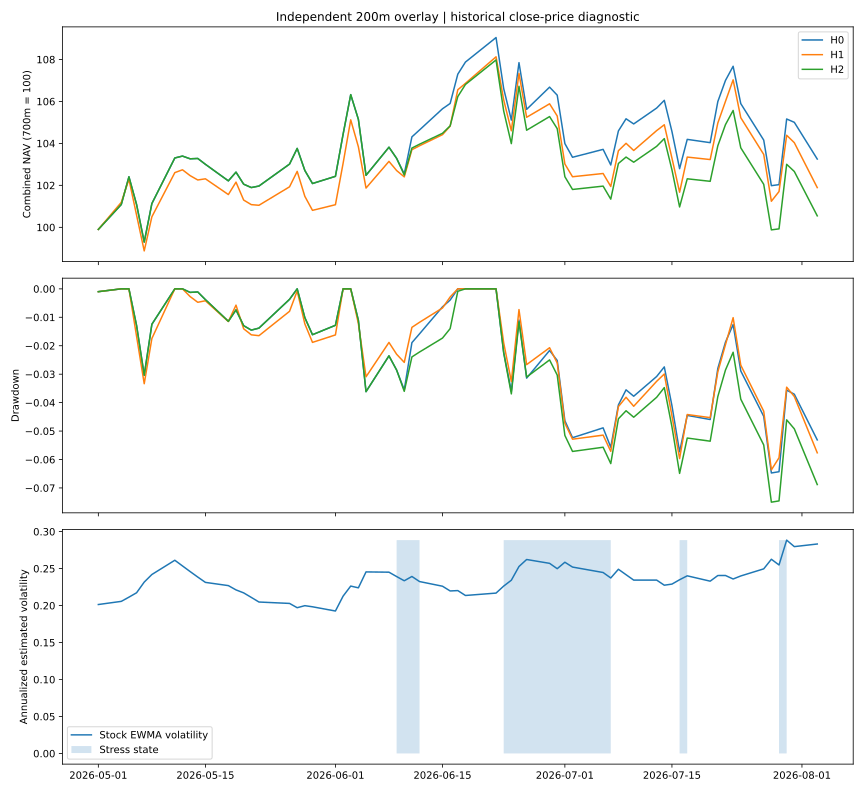

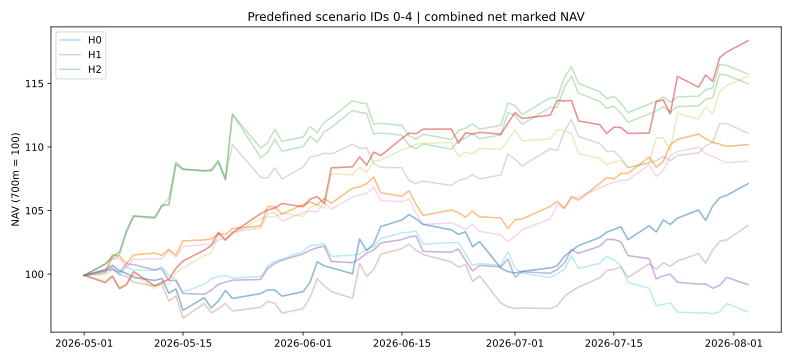

In [3]:
out=Path('aligned_method/hedging')
display(pd.read_csv(out/'actual_metrics.csv'))
display(pd.read_csv(out/'simulation_summary.csv'))
display(pd.read_csv(out/'paired_comparisons.csv'))
for name in ['hedging_states','hedging_scenarios']:
    display(SVG(filename=str(out/'figures'/f'{name}.svg')))

In [4]:
display(pd.read_csv(out/'signals.csv').head())
display(pd.read_csv(out/'trades.csv').head(12))
display(Markdown((out/'report.md').read_text(encoding='utf-8')))
print('Frozen policy hash:',json.loads((out/'run_manifest.json').read_text())['frozen_policy_sha256'])

,Date,volatility,trend_21,state,hedge_active
0,2026-05-01,0.201389,0.122380,normal,False
1,2026-05-04,0.205652,0.122020,normal,False
2,2026-05-05,0.211342,0.099073,normal,False
3,2026-05-06,0.217285,0.106016,normal,False
4,2026-05-07,0.231716,0.101633,normal,False


,date,signal_date,ticker,quantity,price,notional,transaction_cost,kind,hypothetical,strategy
0,2026-05-01,2026-05-01,SGOV,1.981537e+06,98.913124,1.960000e+08,196000.000000,initial_close_diagnostic,False,H0
1,2026-08-03,2026-08-03,SGOV,-1.981537e+06,99.814514,-1.977861e+08,197786.137648,liquidation,True,H0
2,2026-05-01,2026-05-01,SH,5.812143e+06,33.722500,1.960000e+08,196000.000000,initial_close_diagnostic,False,H1
3,2026-08-03,2026-08-03,SH,-5.812143e+06,32.389496,-1.882524e+08,188252.389806,liquidation,True,H1
4,2026-05-01,2026-05-01,SGOV,1.981537e+06,98.913124,1.960000e+08,196000.000000,initial_close_diagnostic,False,H2
5,2026-06-10,2026-06-09,SGOV,-1.981537e+06,99.276939,-1.967209e+08,196720.913437,signal_change,False,H2
6,2026-06-10,2026-06-09,SH,5.928630e+06,33.673428,1.996373e+08,199637.282426,signal_change,False,H2
7,2026-06-16,2026-06-15,SGOV,1.898781e+06,99.336227,1.886178e+08,188617.783165,signal_change,False,H2
8,2026-06-16,2026-06-15,SH,-5.928630e+06,32.564392,-1.930622e+08,193062.221684,signal_change,False,H2
9,2026-06-24,2026-06-23,SGOV,-1.898781e+06,99.415268,-1.887679e+08,188767.863850,signal_change,False,H2


# 獨立風險驅動避險研究

原股票帳戶為 5 億美元，維持原始 12 隻股票及買入持有規則。新增 2 億美元獨立帳戶，合併起始資本 7 億美元。股票帳戶只計算一次，各避險策略共用完全相同的股票持倉及損益。這個基準選擇與再平衡頻率研究分開，不因已知績效選擇最佳頻率。

## 工具與規則

H0：額外資金保留 2% 現金緩衝，其餘買入 SGOV。H1：持續配置 SH，餘額 SGOV。H2：正常狀態持 SGOV；高風險且市場下降狀態轉入 SH；狀態解除時回到 SGOV。只在狀態改變時調整，避免把每日檢查等同每日交易。

SH 是每日 -1x S&P 500 反向 ETF；它持有期貨及交換合約，帳戶本身只買入 ETF，不交易期權。SH 不是現金等價物，跨日報酬有每日重設與複利效應。SGOV 持有 0–3 月國債，提供儲備功能。SPY 只作訊號與 beta 估計。ETF 工具只新增到獨立避險帳戶，原股票帳戶維持 stocks-only。

風險模型為可解釋的正常／壓力雙狀態模型。原目標股票報酬的 EWMA 年化風險超過訓練分布第 75 百分位，且 SPY 過去 21 段報酬累積為負時進入壓力狀態；風險低於第 50 百分位或趨勢轉正時退出。0.94 衰減、21 日趨勢及 75/50 百分位是預先宣告的探索假設，沒有經獨立樣本驗證為最佳。截止日後只更新狀態，不重新估計門檻或 beta。

SH 目標金額為預先估計並截限至 [0,1] 的股票組合對 SPY beta × 5 億美元，上限為當時避險帳戶扣除 2% 緩衝後的金額。因此可能只能部分抵銷股票市場敏感度，個股及空倉急升風險仍存在。交易以訊號日收市資料決定固定數量，下一交易日調整後收市價成交；初始建倉使用訓練末狀態。最後一日優先假設清倉。

## 歷史診斷結果

| strategy   |   net_return |   max_drawdown |   realized_volatility |   excess_return |   tracking_error |   rejected_orders |   overlay_return |   stock_net_return |   overlay_transaction_cost |   overlay_terminal_cost |   hedge_active_fraction |   simulation_percentile |
|:-----------|-------------:|---------------:|----------------------:|----------------:|-----------------:|------------------:|-----------------:|-------------------:|---------------------------:|------------------------:|------------------------:|------------------------:|
| H0         |     0.032529 |      -0.064730 |              0.207676 |        0.030235 |         0.176794 |                 0 |         0.006962 |           0.042756 |              196000.000000 |           197786.137648 |                0.000000 |               40.750000 |
| H1         |     0.018923 |      -0.063650 |              0.202953 |        0.016629 |         0.183004 |                 0 |        -0.040659 |           0.042756 |              196000.000000 |           188252.389806 |                1.000000 |               40.050000 |
| H2         |     0.005467 |      -0.074992 |              0.206829 |        0.003173 |         0.179192 |                 0 |        -0.087755 |           0.042756 |             2832744.492154 |           176324.239723 |                0.296875 |               29.890000 |

![風險狀態與績效](figures/hedging_states.svg)

## 10,000 個共同區塊抽樣情境

股票、基準、SGOV、SH、SPY 使用完全相同歷史日期區塊，保留共同變動。每條路徑獨立過濾狀態；未來價格不得影響較早交易。所有策略使用相同 7 億美元資本，H0 是衡量避險增值的公平比較基準。

| strategy   |   mean_net_return |   median_net_return |       p05 |      p95 |   loss_frequency |   worst5_mean |   mean_max_drawdown |   mean_overlay_cost |   mean_rejected_orders |   mean_hedge_fraction |
|:-----------|------------------:|--------------------:|----------:|---------:|-----------------:|--------------:|--------------------:|--------------------:|-----------------------:|----------------------:|
| H0         |          0.056469 |            0.053528 | -0.074613 | 0.202395 |         0.260600 |     -0.103075 |           -0.058021 |       196000.000000 |               0.000000 |              0.000000 |
| H1         |          0.045717 |            0.040303 | -0.078386 | 0.188366 |         0.308400 |     -0.102159 |           -0.056166 |       196000.000000 |               0.000000 |              1.000000 |
| H2         |          0.052952 |            0.049918 | -0.081068 | 0.198633 |         0.275200 |     -0.112266 |           -0.058671 |       872880.169213 |               0.134600 |              0.120372 |

| comparison   |   mean_difference |       p05 |      p95 |   positive_frequency |
|:-------------|------------------:|----------:|---------:|---------------------:|
| H1 minus H0  |         -0.010752 | -0.040222 | 0.023116 |             0.263500 |
| H2 minus H0  |         -0.003517 | -0.020797 | 0.005217 |             0.104000 |

![共同情境範例](figures/hedging_scenarios.svg)

## 資料與限制

- 訓練：2024-04-29 至 2026-04-28；評估：2026-05-01 至 2026-08-03，63 段報酬。先凍結模型並完成模擬，才載入評估價格。
- 新工具價格為 2026-10-27 下載的 Yahoo 調整後收市價，股息及基金內費用已反映在價格報酬；不再加計股息或另扣基金費用。原股票資料來源及公司行動仍未獨立驗證。
- 原股票帳戶現金、空倉所得與抵押繼續獨立記帳；2 億美元是新增資本，沒有跨帳戶挪用或注資。股票費用沿用 10 bps 與示意 2% 年借券費。
- ETF 交易成本為示意 10 bps 實際交易額。2% 現金緩衝是研究假設；若固定訂單在價差後資金不足，拒絕整筆轉倉、保留持倉、記錄拒單，下一日以新取得的前收市資訊重試；無假設融資、追溯縮單或刪除路徑。
- 本研究是調整後價格理想化診斷，使用合成分數單位；不代表已驗證的開盤成交或券商實盤。2 億美元 SH 訂單的市場容量、價差及衝擊尚未驗證。
- 2026 評估結果早已被研究過；這是歷史診斷比較，工具與模型也是回顧性研究選擇。原計算、notebook、再平衡分支與輸出均保留。
- SH 官方：https://www.proshares.com/our-etfs/leveraged-and-inverse/sh
- SGOV 官方：https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf


Frozen policy hash: 74cc2284a07d922494209da17a74067e8d5a6e88c1ae4b2bd4f8bcf411e74ea2


## ????

?? ETF ????????????????????????????????????????????? H0 ??????????? 5% ??????

??????????????????????????????????????????????????????????????????????